# Seaborn for statistical plots

`seaborn` is a statistical visualisation library that builds on top of `matplotlib`.

The package provides some default settings for `matplotlib` that are designed to improve how your plots look.  Although that is subjective! 

More importantly it aims to simplify creating statistical plots in `matplotlib`.  It does this by providing functions that minimise the amount of both data wrangling and plotting code you need to write.

> **From the seaborn documentation:** While you can be productive using only seaborn functions, full customization of your graphics will require some knowledge of matplotlib’s concepts and API. One aspect of the learning curve for new users of seaborn will be knowing when dropping down to the matplotlib layer is necessary to achieve a particular customization. On the other hand, users coming from matplotlib will find that much of their knowledge transfers.

It is a big library and here we will only have a brief introduction. You can view `seaborn` documentation [here](https://seaborn.pydata.org/index.html)

## 1. Imports

In [1]:
import seaborn as sns

# This will set default style for matplotlib
sns.set_theme()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the ED datasets from week 8

In [3]:
LONG_URL = 'https://raw.githubusercontent.com/health-data-science-OR/' \
            + 'hpdm139-datasets/main/syn_ts_ed_long.csv'
WIDE_URL = 'https://raw.githubusercontent.com/health-data-science-OR/' \
            + 'hpdm139-datasets/main/syn_ts_ed_wide.csv'

In [4]:
long_df = pd.read_csv(LONG_URL)

# shortcut - we will set the index to date as we read in and parse it.
# you should only do this if you know it is valid dates.
wide_df = pd.read_csv(WIDE_URL, index_col='date', parse_dates=True)

## 3. `seaborn` defaults

At the top of the notebook we called `sns.set_theme()`. Compare the code and outputs of the below to the code and output of week 8 exercise 4.

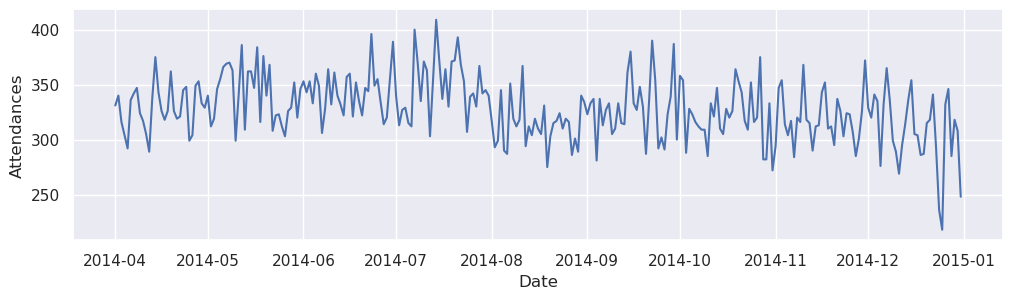

In [5]:
fig = plt.figure(figsize=(12,3))
ax = fig.add_subplot()
ax.set_xlabel("Date")
ax.set_ylabel("Attendances")

_ = ax.plot(wide_df['hosp_1'])

## 4. The Relational Plot Function

A common use of `seaborn` is to make use of its relational plot or `sns.relplot()`. This is a function that allows us to plot relationships between variables (e.g. a scatter) but can also look at more differences across categories like we had with ED hospital id via a line plot.

**Using relplot with tidy data**

Let's solve week 8 exercise 5 with `seaborn`. However, instead of using `matplotlib` and wide format data we will use `sns.relplot()` and tidy/long data.  

One thing to remember is that by default `pandas` treats the `date` column as a string (the `object` datatype).  In week 8 we spent time learning how to convert strings of dates to a  `datetime` format. There was a good reason for this to do with the visualising time on the x-axis. Let's ignore it first and see what happens.

In [6]:
long_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   date     1100 non-null   object
 1   hosp     1100 non-null   int64 
 2   attends  1100 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 25.9+ KB


* When we call `relplot` the parameter `row` represents the categories we would like to separate into different axes plots.  Here it is the `hosp` column.
* We will set the `kind` of plot to `line` for time series data
* In `relplot` we do not have a `figsize` parameter instead we have `height` and `aspect`. If `height=2` and `aspect=5` we get a 10x2 inches image for each subplot.

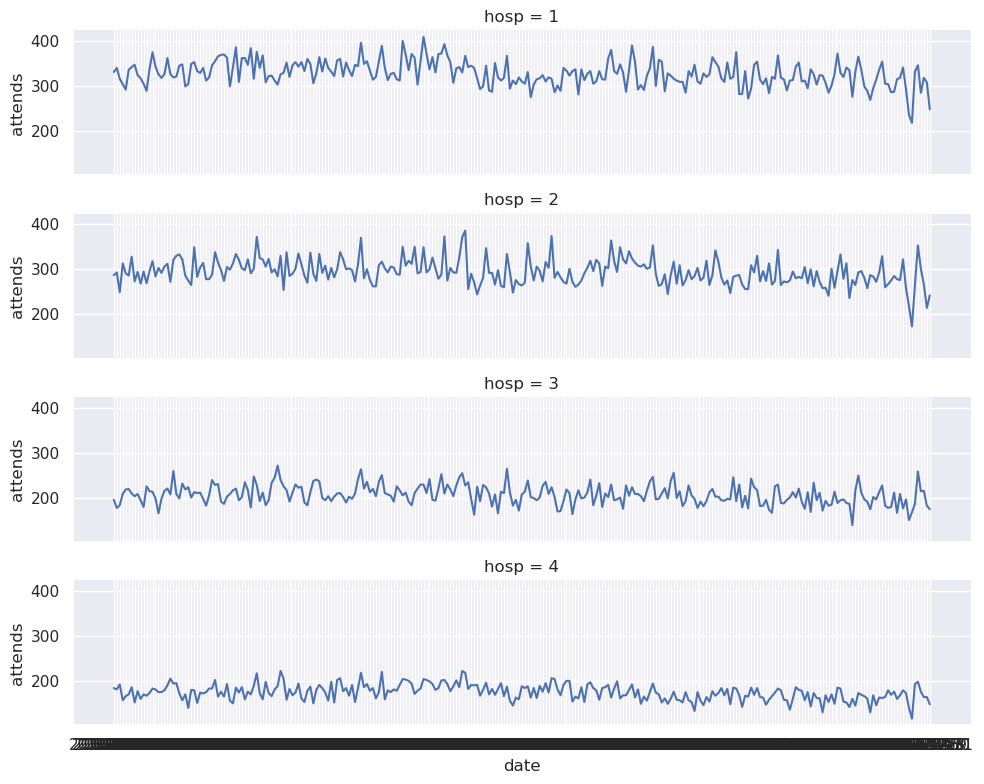

In [7]:
g = sns.relplot(
    data=long_df, 
    x="date", 
    y="attends", 
    row="hosp",  # split into separate axis objects 
    kind="line",
    height=2, 
    aspect=5,
)

The x-axis is unusable because we didn't convert the date string to a proper datetime datatype and `seaborn` has tried to plot every single label for each date.  Recall that we used `assign` and a **lambda expression** in week 8 to convert a date.

In [8]:
# let's make sure our date is recognised by seaborn and pandas.
long_df = long_df.assign(date=lambda d: pd.to_datetime(d["date"]))

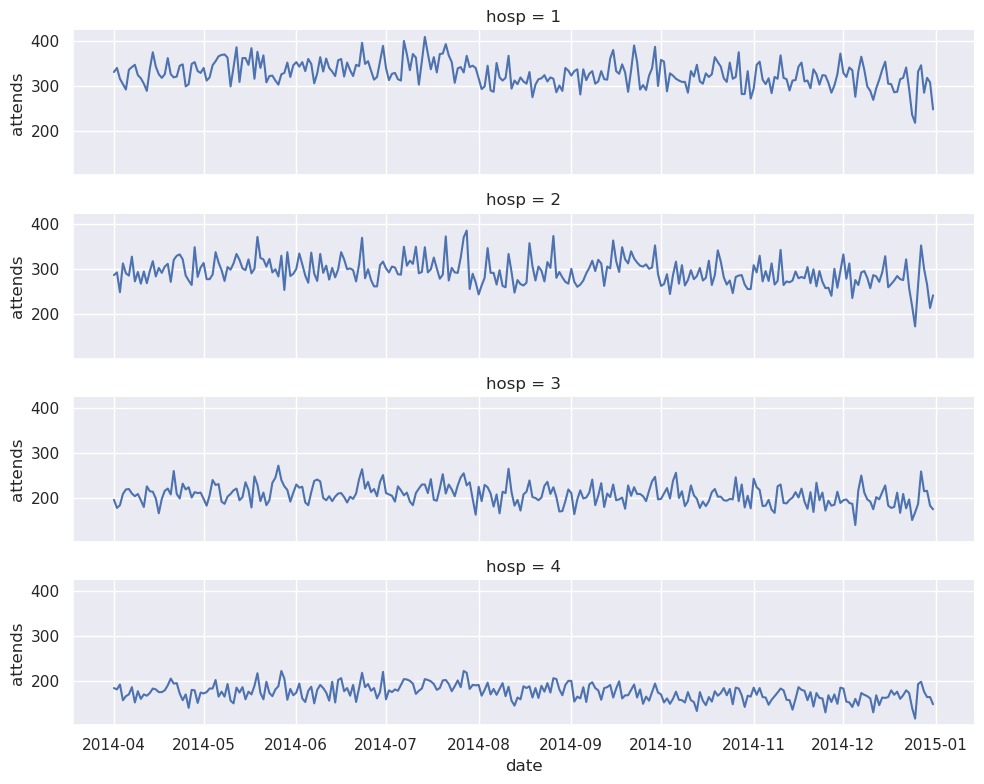

In [9]:
g = sns.relplot(
    data=long_df, 
    x="date", 
    y="attends", 
    row="hosp", 
    kind="line",
    height=2, 
    aspect=5,
)

**Adding Figure, subplot and axis labels**

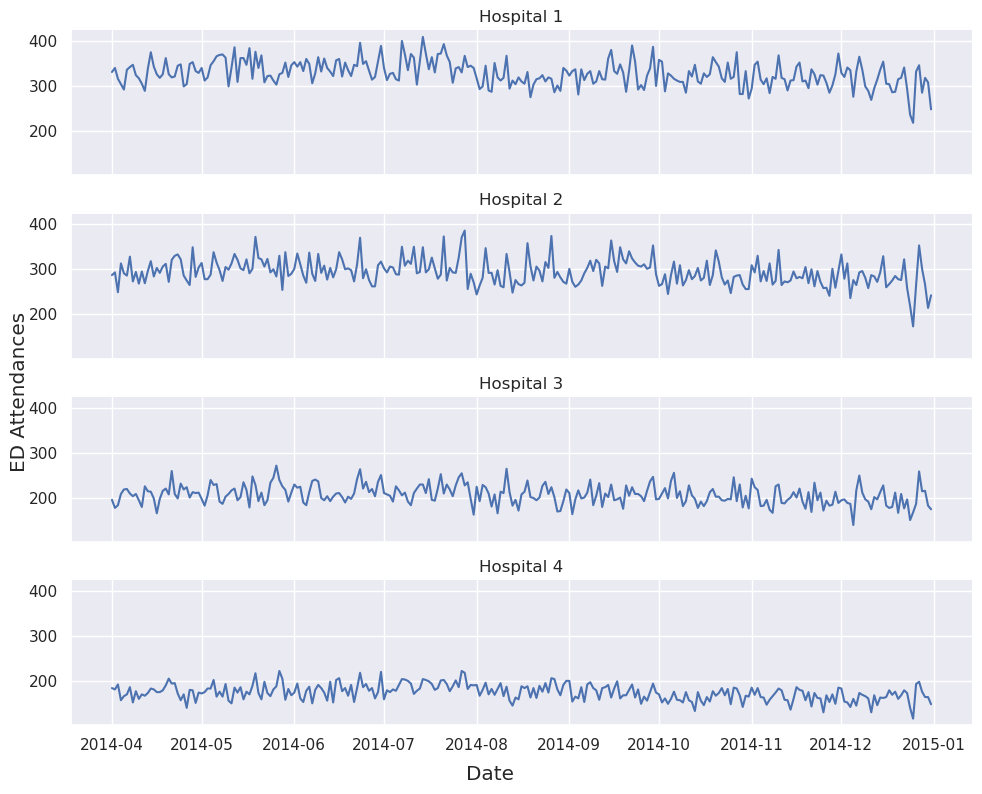

In [10]:
g = sns.relplot(
    data=long_df, 
    x="date", 
    y="attends", 
    row="hosp", 
    kind="line",
    height=2, 
    aspect=5,
)

# New code for labels and titles
_ = g.set_titles("Hospital {row_name}") 

#  setting overall labels
_ = g.set_axis_labels("", "")          # remove the per-panel labels
_ = g.figure.supxlabel("Date")
_ = g.figure.supylabel("ED Attendances")

## 5. A categorical plot

The `hosp` column is a categorical variable.  If we set that up properly in `pandas` we can then make use of a `sns.catplot()` and create a box and whisker plot or a violin plot. 

In [11]:
# set hosp to be of type Categorical
long_df = long_df.assign(hosp=lambda d: pd.Categorical(d["hosp"]))

In [12]:
long_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     1100 non-null   datetime64[ns]
 1   hosp     1100 non-null   category      
 2   attends  1100 non-null   int64         
dtypes: category(1), datetime64[ns](1), int64(1)
memory usage: 18.6 KB


### 5.1. Box plot

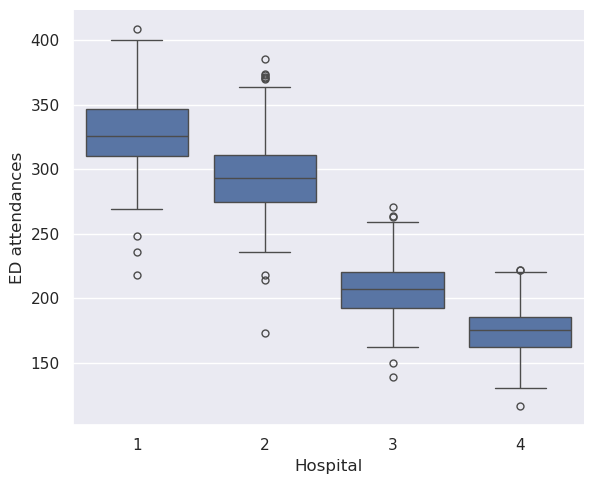

In [13]:
g = sns.catplot(
    data=long_df,
    x="hosp", # the categories on the x-axis
    y="attends",
    kind="box",      # or "violin"
    height=5,
    aspect=1.2,
)

_ = g.set_axis_labels("Hospital", "ED attendances")

### 5.2 Violin plot

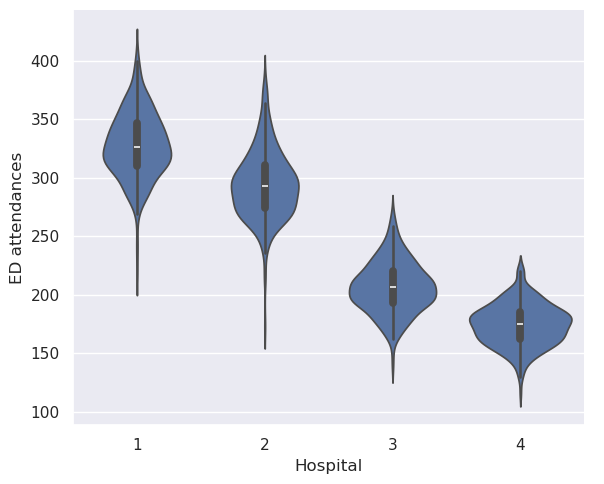

In [14]:
g = sns.catplot(
    data=long_df,
    x="hosp",
    y="attends",
    kind="violin",  # modification
    height=5,
    aspect=1.2,
)

_ = g.set_axis_labels("Hospital", "ED attendances")

### 5.3 Let's look at seasonal patterns in the time series

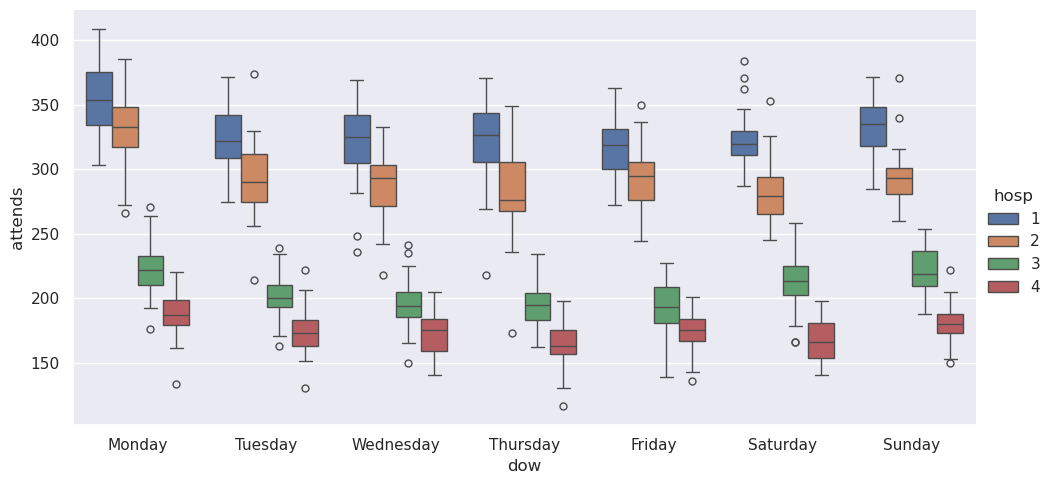

In [15]:
# create day of week 'dow' column
long_df = long_df.assign(dow=lambda d: d["date"].dt.day_name(),)

# we need this to make seaborn display the days in order.
order = ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"]

g = sns.catplot(
    data=long_df,
    x="dow", 
    y="attends", 
    hue="hosp",  # split by hospital category
    kind="box",
    order=order,
    height=5, 
    aspect=2,
)

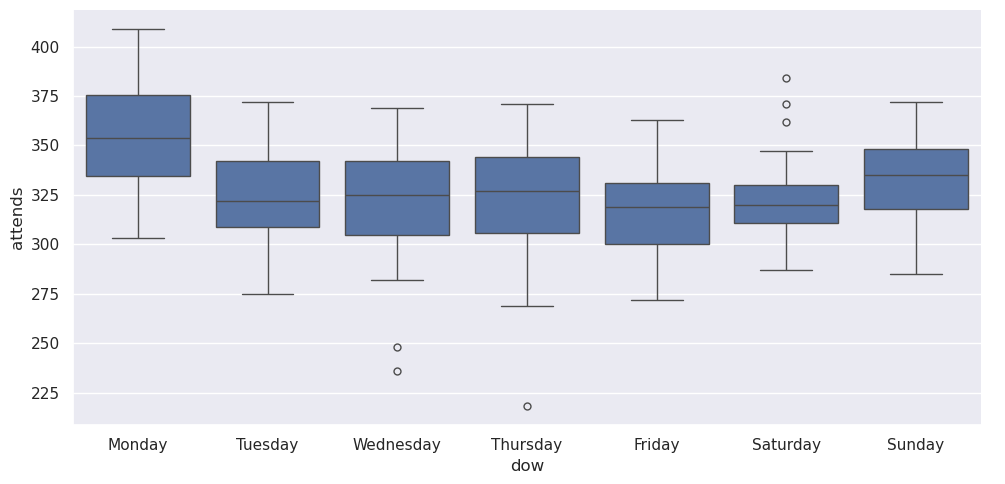

In [16]:
# if you wanted to look at a single hospital you would use pandas to filter

# note we dropped `hue`

g = sns.catplot(
    data=long_df[long_df['hosp']==1], # pandas filtering
    x="dow", 
    y="attends", 
    kind="box",
    order=order,
    height=5, 
    aspect=2,
)

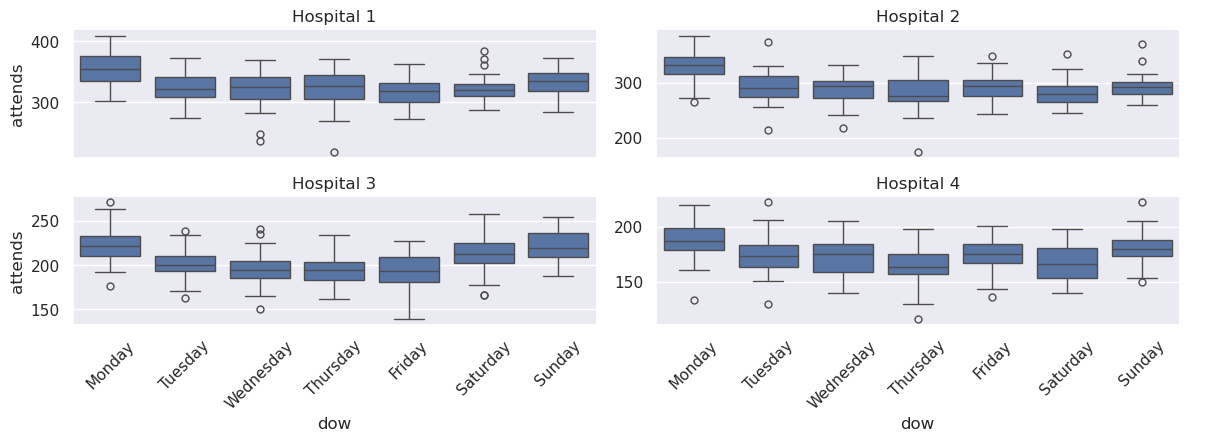

In [17]:
# or we could use the row or col parameter for a plot per category.
# lets use col here and output a 2 x 2 grid.

g = sns.catplot(
    data=long_df,
    x="dow", 
    y="attends", 
    col="hosp",  # updated from row to col
    col_wrap=2,  # 2 per row
    kind="box",
    order=order,
    height=2, 
    aspect=3,
    sharey=False,
)

_ = g.set_titles("Hospital {col_name}")
_ = g.tick_params(axis="x", rotation=45)

## 6. Dropping down to `matplotlib`

If we capture the output of a `seaborn` call to either `relplot` or `catplot` we have a `FacetGrid`

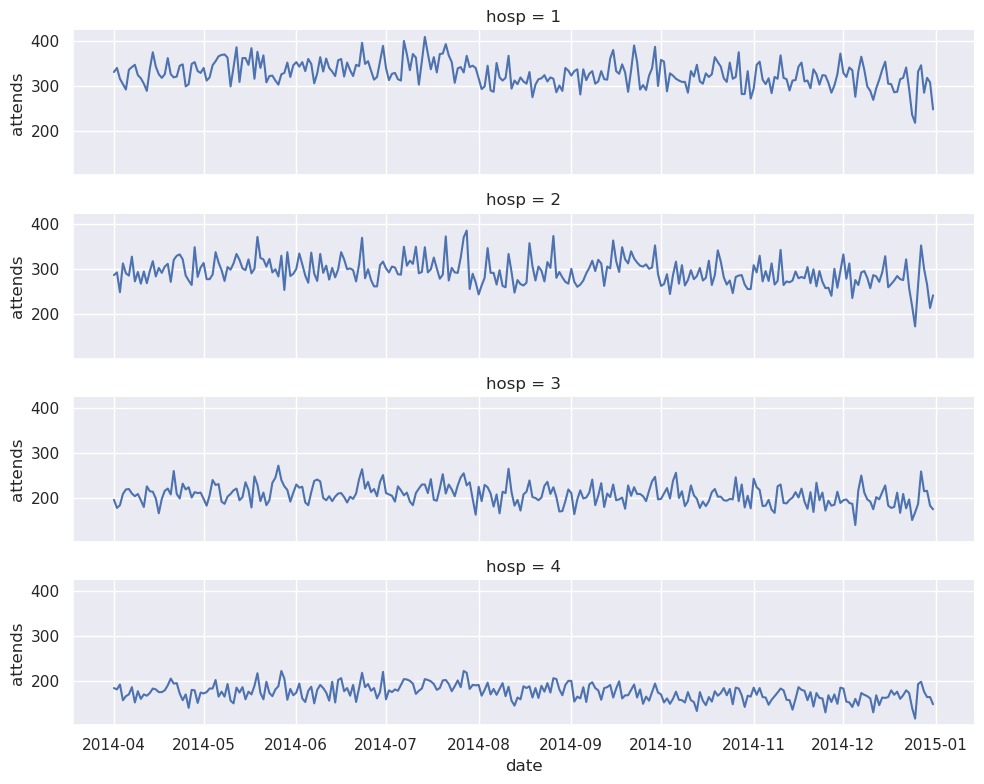

In [18]:
# assign the return value of the replot to the variable `g`
g = sns.relplot(
    data=long_df, 
    x="date", 
    y="attends", 
    row="hosp", 
    kind="line",
    height=2, 
    aspect=5,
)

In [19]:
# g is of type FacetGrid. This is a seaborn datatype
type(g)

seaborn.axisgrid.FacetGrid

In [20]:
# underneath it we can access the matplotlib figure object
type(g.figure)

matplotlib.figure.Figure

In [21]:
# and we have multiple axes objects for the 4 subplots inside an 2d array
g.axes

array([[<Axes: title={'center': 'hosp = 1'}, ylabel='attends'>],
       [<Axes: title={'center': 'hosp = 2'}, ylabel='attends'>],
       [<Axes: title={'center': 'hosp = 3'}, ylabel='attends'>],
       [<Axes: title={'center': 'hosp = 4'}, xlabel='date', ylabel='attends'>]],
      dtype=object)

In [22]:
type(g.axes)

numpy.ndarray

In [23]:
# it is 2D.  In this case 4 rows and 1 column
g.axes.shape

(4, 1)

In [24]:
type(g.axes[0])

numpy.ndarray

In [25]:
# finally we have a subplot object!
type(g.axes[0][0])

matplotlib.axes._axes.Axes

In [26]:
# it is hospital 1
g.axes[0][0]

<Axes: title={'center': 'hosp = 1'}, ylabel='attends'>

Use `matplotlib` for extra customisation.  For example, the code below modifies the hospital 1 plot.

1. Adds a vertical red band for the Christmas period in 2014
2. Adds horizontal black dashed line representing mean attendances.

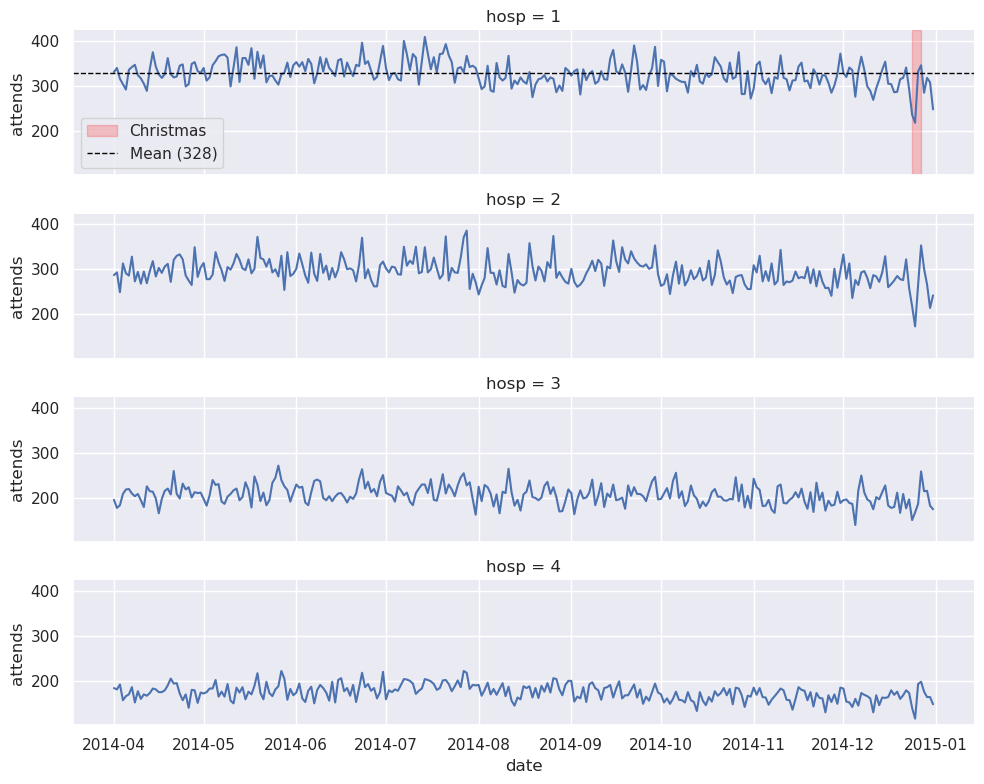

In [27]:
# example manipulating hospital 1
g = sns.relplot(
    data=long_df, 
    x="date", 
    y="attends", 
    row="hosp", 
    kind="line",
    height=2, 
    aspect=5,
)

# get hospital one matplolib axis from seaborn FacetGrid
ax = g.axes[0][0]

# 1. Highlight a period, e.g. Christmas
_ = ax.axvspan(
    pd.Timestamp("2014-12-24"), 
    pd.Timestamp("2014-12-27"),
    color="red", 
    alpha=0.2, 
    label="Christmas"
)

# 2. Mean attendances
mean_h1 = long_df[long_df['hosp']==1]["attends"].mean()
_ = ax.axhline(
    mean_h1, 
    color="black", 
    ls="--", 
    lw=1, 
    label=f"Mean ({mean_h1:.0f})"
)

# 3. Add a legend to the plot
_ = ax.legend(loc="lower left")

## 7. Saving an image

In [28]:
# via the matplotlib figure object
g.figure.savefig("attendances.png", dpi=300, bbox_inches="tight")

In [29]:
# or equivalently via the seaborn interface
g.savefig("attendances.png", dpi=300, bbox_inches="tight")

## 8. Distribution plot

### 8.1 Simple histogram of results

Recall in week 5 we looked at sampling from statistical distributions. If we wanted to plot those samples and examine the distribution we could use `sns.displot`.  For example, if we wanted to plot the distribution of samples we had taken from the exponential distribution.

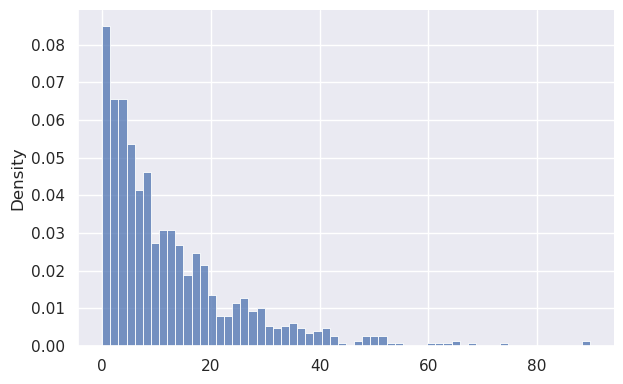

In [30]:
# 1. simulation
rng = np.random.default_rng(42)    
samples = rng.exponential(scale=12, size=1000)

# 2. seaborn automatically creates a histogram for you
g = sns.displot(
    x=samples, 
    kind='hist', 
    stat="density",   # use count for absolute no. samples
    bins=60, 
    height=4, 
    aspect=1.6
)

### 8.2 Adding a 2nd series to the histogram

Let's compare the sampled values to the theoretical PDF of the exponential distribution. We will define a function to generate those values called `exponential_pdf`.

To add the theoretical distribution to the histogram generated by `seaborn` we need to drop down to `matplotlib` and use `ax.plot()`.

In [31]:
def exponential_pdf(x, scale):
    """Theoretical exponential probability density: 
    (1/scale) * exp(-x/scale)."""
    return np.exp(-x / scale) / scale

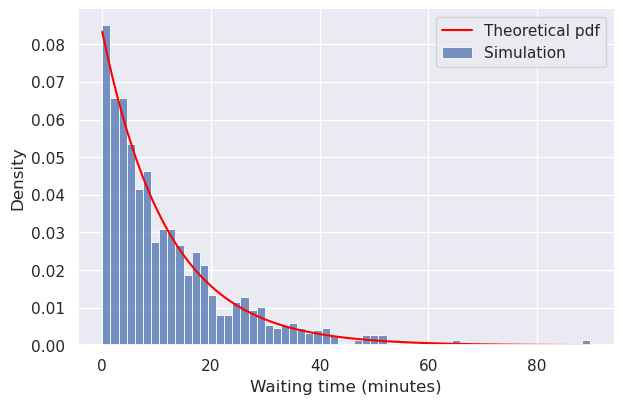

In [32]:
SCALE = 12   # mean waiting time (minutes)

# 1. simulation
rng = np.random.default_rng(42)    
samples = rng.exponential(scale=SCALE, size=1000)

# 2. get theoretical 
x_values = np.linspace(0, samples.max(), 100)
pdf_values = exponential_pdf(x_values, SCALE)

# 3. histogram of samples
g = sns.displot(
    x=samples, 
    kind='hist', 
    stat="density", 
    bins=60, 
    height=4, 
    aspect=1.6,
    label="Simulation",
)

# 4. add theoretical curve via matplotlib axis object
# there is only a single plot so use g.ax instead of g.axes
_ = g.ax.plot(x_values, pdf_values, color="red", label="Theoretical pdf")
_ = g.ax.legend()
_ = g.set_axis_labels("Waiting time (minutes)", "Density")

For more general detail on `seaborn` checkout the official documentation https://seaborn.pydata.org/tutorial/function_overview.html 